# ChromBPNet: bias-factorised base-resolution accessibility models

ChromBPNet (Pampari *et al.*; [kundajelab/chrombpnet](https://github.com/kundajelab/chrombpnet), MIT) predicts the base-resolution ATAC-seq profile and total counts of a 1,000-bp window from 2,114 bp of DNA. It uses two convolutional networks:

* a small **bias model** trained on GC-matched background regions, where the Tn5 enzyme's sequence preference dominates;
* an **accessibility model** that learns everything else.

Their profile logits add up, and their counts combine with `logsumexp`. Dropping the bias model leaves a *bias-corrected* model whose predictions, contributions and footprints reflect TF binding rather than Tn5 preference.

`epione.models.chrombpnet` is a **PyTorch** rewrite of the official TensorFlow code. TensorFlow is never imported.

* Official `.h5` models, including ENCODE's released ones, load through `h5py`.
* The data recipe (GC-matched non-peaks, hyper-parameter steps, jitter and reverse-complement batches) and the training recipe follow the official code.
* Signal is read straight from a fragments file, with no bigWig export.
* The bias model also plugs into Epione's footprinting as a Tn5 bias backend: `epi.tl.tn5_bias(method="chrombpnet")`.

Validation against the official implementation is summarised at the end.

In [1]:
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MaxNLocator
from scanpy.plotting.palettes import default_20 as PALETTE

import epione as epi
from epione.models import chrombpnet as cbp

epi.pl.plot_set()

torch.set_num_threads(8)
device = "cuda" if torch.cuda.is_available() else "cpu"
genome = epi.data.hg38
fasta = str(genome.fasta)
sizes = {c: s for c, s in genome.chrom_sizes.items() if re.fullmatch(r"chr(\d+|X|Y)", c)}
print(device)

# One colour per model, fixed across all figures (colour-blind-safe picks from epi.pl.sc_color).
MODEL_COLORS = {"full model": "#279AD7", "bias model": "#EF7B77", "bias-corrected": "#368650",
                "PRINT bias": "#5E4D9A"}
bp = FuncFormatter(lambda v, _: f"{v:,.0f}")  # genomic positions with thousands separators

└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.



cuda


## Data

The 10x Multiome PBMC 3k sample: about 40 million fragments, pooled over all cells, give a bulk-like ATAC track. `InsertionSignal` reads per-base Tn5 cuts from the fragments file on demand.

For 10x fragments the official pipeline builds its training bigWig with cuts at each fragment's `start` and `end`: its auto-detected +4/-5 input shift plus its +4/-4 target shift. That is `shift=(0, 0)`, the default. On 2,000 random 1-kb windows these reads equal the official pipeline's bigWig exactly; see the summary at the end.

In [2]:
data = epi.datasets.pbmc3k_multiome_atac()
signal = cbp.InsertionSignal(data["fragments"], sizes)

peaks = pd.read_csv(data["peaks"], sep="\t", comment="#", header=None, usecols=[0, 1, 2],
                    names=["chr", "start", "end"])
peaks = peaks[peaks["chr"].isin(sizes)].reset_index(drop=True)
# ChromBPNet centres windows on peak summits; the 10x peak file has none, so use the centre.
for col in ["1", "2", "3", "4", "5", "6"]:
    peaks[col] = "."
peaks["summit"] = (peaks["end"] - peaks["start"]) // 2
print(len(peaks), "peaks")

98290 peaks


## A pretrained ENCODE model

`load_pretrained` downloads one of ENCODE's ChromBPNet releases, here GM12878 (ENCODE annotation ENCSR081YFO). The download is pinned by accession and md5 and loaded without TensorFlow.

* `"chrombpnet"` is the full model.
* `"nobias"` is the bias-corrected accessibility model, which ENCODE recommends for biological discovery.
* `"bias"` is the Tn5 bias model.

Same-weights parity: on 512 fixed sequences, the PyTorch outputs match the official Keras outputs with mean profile Jensen–Shannon distance ≤ 5.5e-7.

In [3]:
model = cbp.load_pretrained("encode_gm12878", "chrombpnet", fold=0).to(device)
nobias, bias = model.accessibility, model.bias
print(model.bias.filters, "x", model.bias.n_dil_layers, "bias;",
      model.accessibility.filters, "x", model.accessibility.n_dil_layers, "accessibility")

128 x 4 bias; 512 x 8 accessibility


GM12878 is a lymphoblastoid cell line, so on PBMC peaks the model predicts a related but different cell population. On the held-out chromosomes of ENCODE fold 0 (chr1, chr3, chr6) we compare predicted with observed log counts.

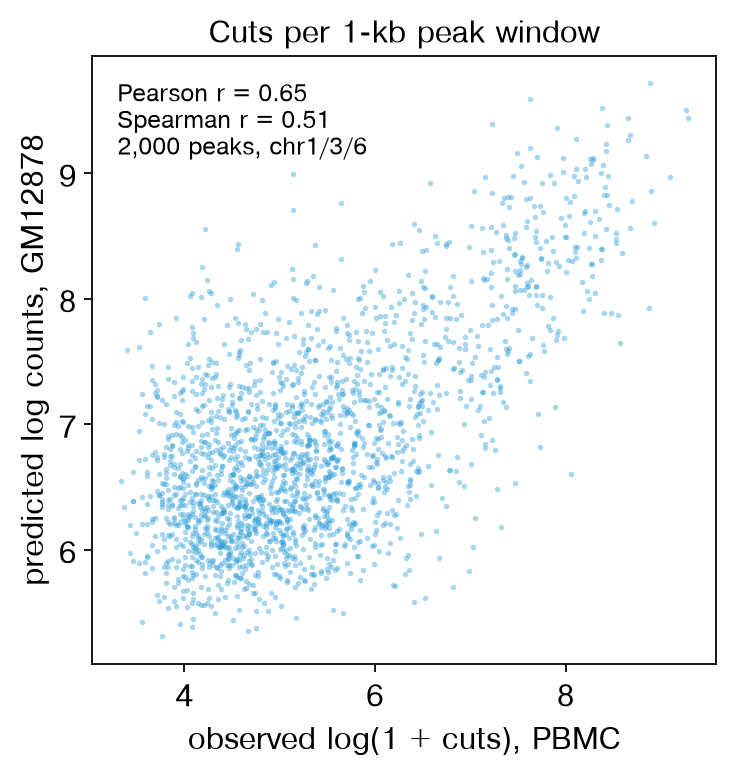

{'count_pearson': 0.6506459667503954,
 'count_spearman': 0.5116349945329324,
 'count_mse': 3.1535359862549885,
 'profile_median_jsd': 0.5523481881993038,
 'n_regions': 2000}

In [4]:
test = cbp.filter_edge_regions(peaks[peaks["chr"].isin(["chr1", "chr3", "chr6"])], sizes, 2114)
test = test.sample(n=2000, random_state=0).sort_values(["chr", "start"])
m = cbp.evaluate(model, test, fasta, signal, device=device)
pred = cbp.predict_regions(model, test, fasta, device=device)
obs = np.log1p(np.array([signal.values(c, s + smt - 500, s + smt + 500).sum()
                         for c, s, smt in zip(test["chr"], test["start"], test["summit"])]))
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(obs, pred["log_counts"], s=6, alpha=0.4, lw=0, color=MODEL_COLORS["full model"])
ax.set_xlabel("observed log(1 + cuts), PBMC")
ax.set_ylabel("predicted log counts, GM12878")
ax.set_title("Cuts per 1-kb peak window")
ax.text(0.04, 0.96, f"Pearson r = {m['count_pearson']:.2f}\n"
        f"Spearman r = {m['count_spearman']:.2f}\n{m['n_regions']:,} peaks, chr1/3/6",
        transform=ax.transAxes, va="top", fontsize=11)
plt.show()
m

## Bias-corrected profiles

At one strong peak, the full model reproduces the observed cut profile. The bias model on its own gives the jagged, sequence-driven Tn5 pattern. The bias-corrected model removes it and leaves the accessibility signal, with footprints at bound sites.

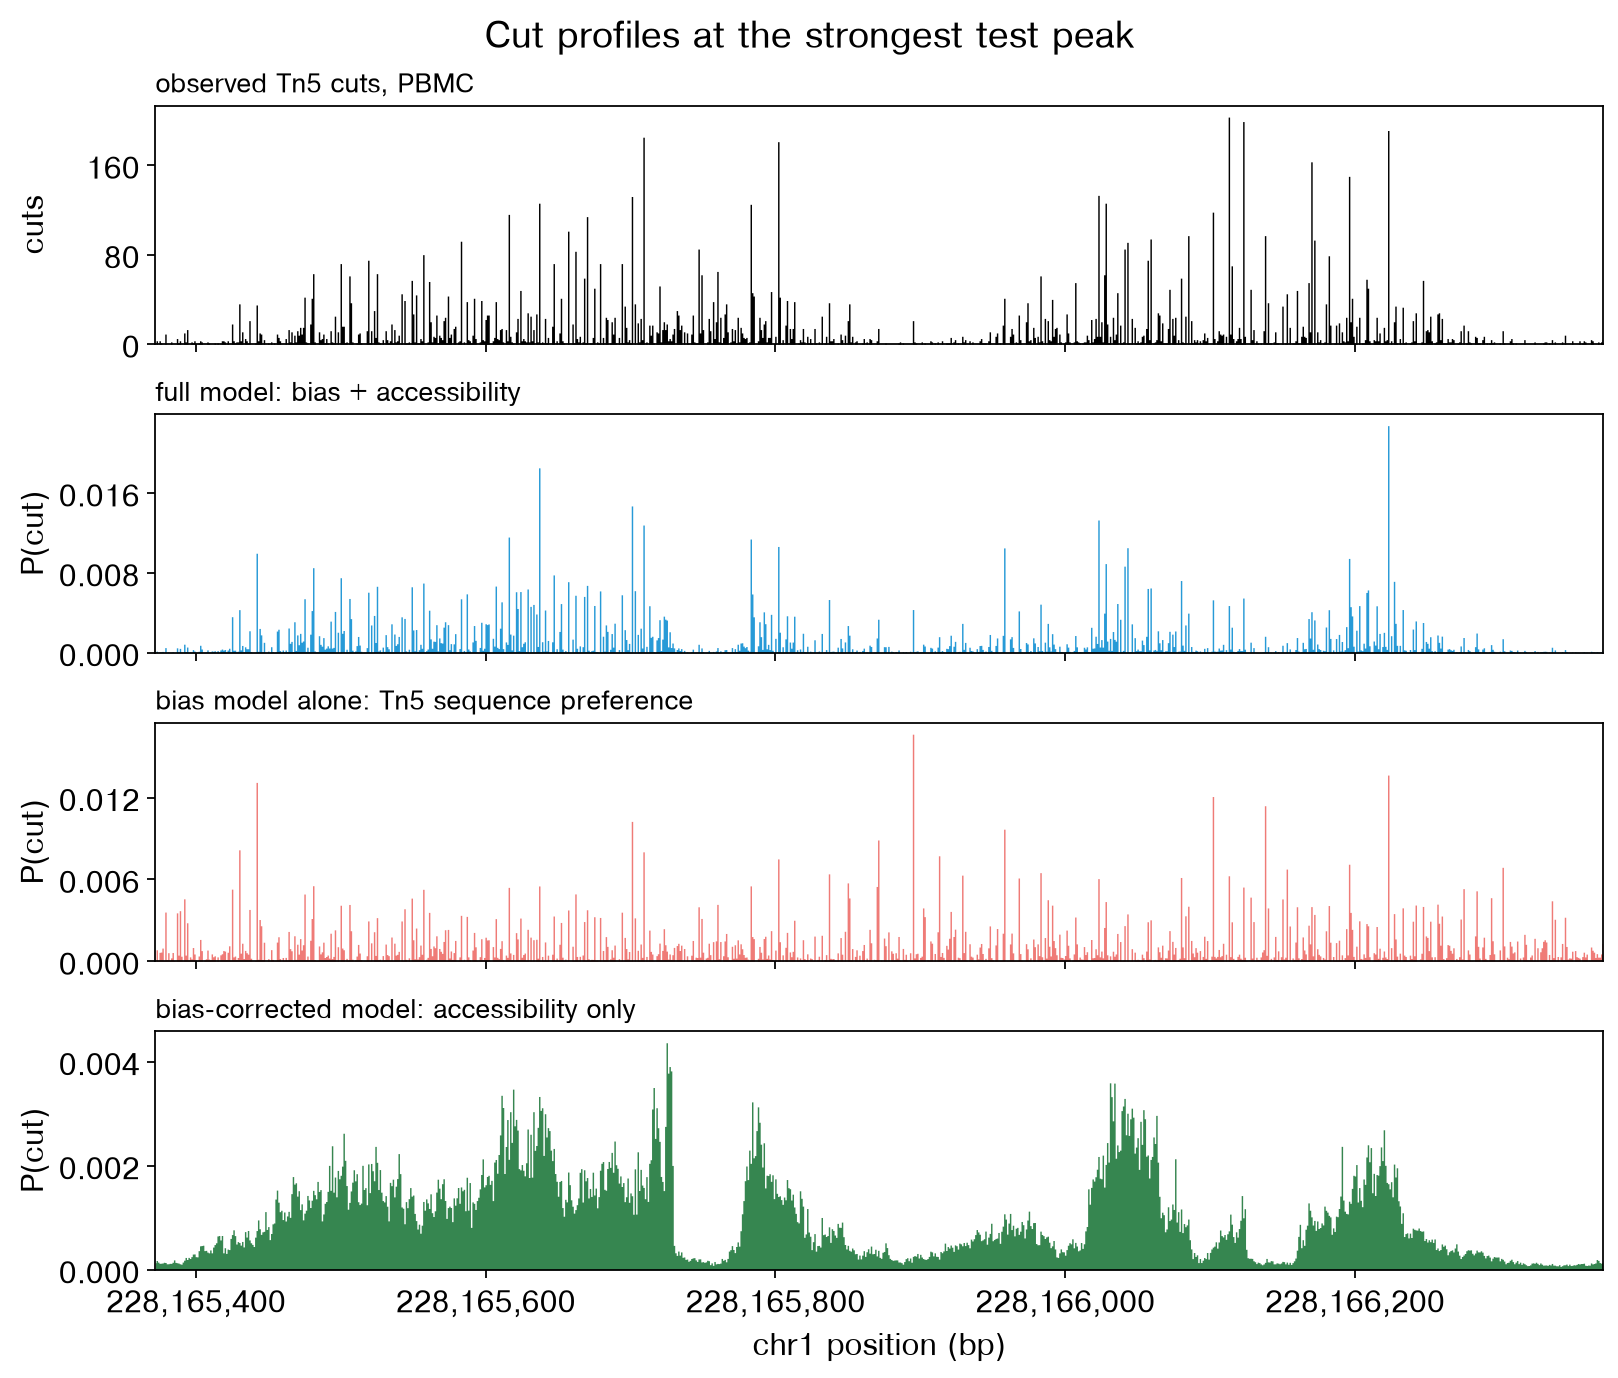

In [5]:
top = test.assign(obs=obs).sort_values("obs", ascending=False).iloc[0]
seq = cbp.get_seq_onehot(pd.DataFrame([top]), fasta, 2114)
x = torch.as_tensor(np.transpose(seq, (0, 2, 1)), dtype=torch.float32, device=device)
with torch.no_grad():
    tracks = {name: torch.softmax(net(x)[0], -1)[0].cpu().numpy()
              for name, net in [("full model", model), ("bias model", bias),
                                ("bias-corrected", nobias)]}
centre = top["start"] + top["summit"]
o = signal.values(top["chr"], centre - 500, centre + 500)
gpos = np.arange(centre - 500, centre + 500)
panels = [("observed Tn5 cuts, PBMC", o, "black", "cuts"),
          ("full model: bias + accessibility", tracks["full model"],
           MODEL_COLORS["full model"], "P(cut)"),
          ("bias model alone: Tn5 sequence preference", tracks["bias model"],
           MODEL_COLORS["bias model"], "P(cut)"),
          ("bias-corrected model: accessibility only", tracks["bias-corrected"],
           MODEL_COLORS["bias-corrected"], "P(cut)")]
fig, axes = plt.subplots(4, 1, figsize=(10, 8.5), sharex=True, layout="constrained")
for ax, (title, y, color, ylabel) in zip(axes, panels):
    ax.fill_between(gpos, 0, y, step="mid", color=color, lw=0)
    ax.set_ylim(0, None)
    ax.yaxis.set_major_locator(MaxNLocator(3))
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", fontsize=12)
axes[-1].set_xlim(gpos[0], gpos[-1])
axes[-1].xaxis.set_major_locator(MaxNLocator(5))
axes[-1].xaxis.set_major_formatter(bp)
axes[-1].set_xlabel(f"{top['chr']} position (bp)")
fig.suptitle("Cut profiles at the strongest test peak")
fig.align_ylabels(axes)
plt.show()

## Which bases matter: in-silico mutagenesis

`cbp.ism` mutates every base in the central 120 bp and records the change in the bias-corrected model's predicted log counts. The importance of a base is minus the mean effect of its three substitutions. `cbp.contribution_scores` gives the official DeepLIFT-SHAP scores instead (requires `captum`); ISM needs nothing extra.

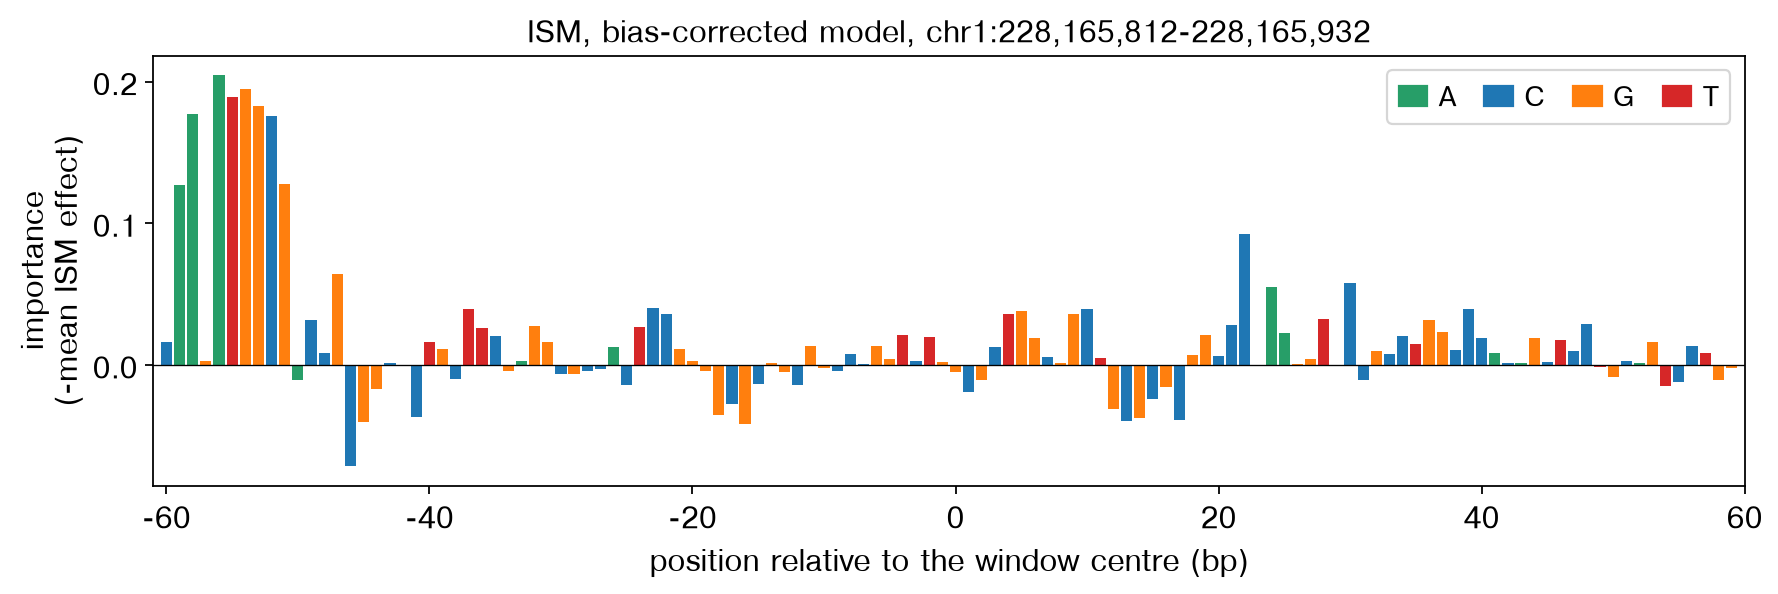

In [6]:
pos = np.arange(1057 - 60, 1057 + 60)
eff = cbp.ism(nobias, seq[0], positions=pos, device=device)
imp = -eff.sum(1) / 3
bases = np.array(list("ACGT"))[seq[0][pos].argmax(1)]
# Usual nucleotide colours (A green, C blue, G orange, T red), from scanpy's default palette.
base_colors = {"A": PALETTE[2], "C": PALETTE[0], "G": PALETTE[1], "T": PALETTE[3]}
rel = pos - 1057
fig, ax = plt.subplots(figsize=(11, 3.6), layout="constrained")
ax.bar(rel, imp, color=[base_colors[b] for b in bases], width=0.85, lw=0)
ax.axhline(0, color="black", lw=0.6)
ax.set_xlim(rel[0] - 1, rel[-1] + 1)
ax.set_xlabel("position relative to the window centre (bp)")
ax.set_ylabel("importance\n(-mean ISM effect)")
ax.set_title(f"ISM, bias-corrected model, {top['chr']}:{centre - 60:,}-{centre + 60:,}")
ax.legend(handles=[Patch(color=c, label=b) for b, c in base_colors.items()],
          ncol=4, loc="upper right", handlelength=1, columnspacing=1)
plt.show()

## Marginal footprint of CTCF

Insert the CTCF consensus (JASPAR MA0139.1) into 300 dinucleotide-shuffled peak backgrounds and average the predicted profiles. `depth` is the centre-to-flank ratio of predicted cut probability; below 1 means a footprint.

For CTCF, the full and bias-corrected models give nearly the same deep footprint. The motif's footprint is far stronger than Tn5's preference around it. Removing the bias matters most for weaker footprints and for motifs whose own sequence Tn5 prefers or avoids; there the full model's profile is partly bias.

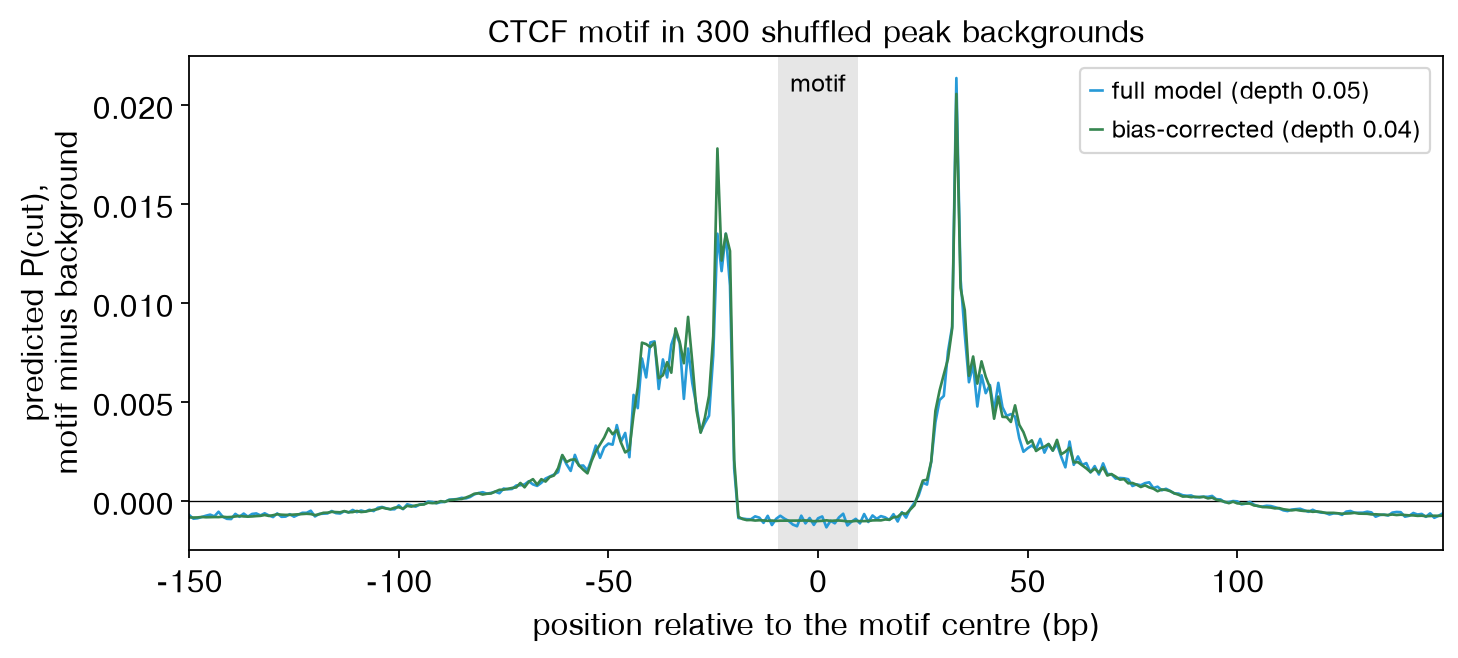

In [7]:
rng = np.random.RandomState(0)
bg = cbp.get_seq_onehot(test.sample(n=300, random_state=1), fasta, 2114)
bg = np.stack([cbp.dinuc_shuffle(s, 1, rng)[0] for s in bg])
ctcf = "TGGCCACCAGGGGGCGCTA"
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.axvspan(-len(ctcf) / 2, len(ctcf) / 2, color="0.9", lw=0)
ax.text(0, 0.97, "motif", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=11)
ax.axhline(0, color="black", lw=0.6)
for name, net in [("full model", model), ("bias-corrected", nobias)]:
    fp = cbp.marginal_footprint(net, ctcf, backgrounds=bg, device=device)
    d = fp["profile_with_motif"] - fp["profile_background"]
    ax.plot(np.arange(-150, 150), d[350:650], color=MODEL_COLORS[name], lw=1.2,
            label=f"{name} (depth {fp['depth']:.2f})")
ax.set_xlim(-150, 149)
ax.set_xlabel("position relative to the motif centre (bp)")
ax.set_ylabel("predicted P(cut),\nmotif minus background")
ax.set_title("CTCF motif in 300 shuffled peak backgrounds")
ax.legend(loc="upper right", fontsize=11)
plt.show()

## Training on your own data

The official recipe has three parts:

1. GC-matched background regions (`gc_matched_nonpeaks`, ratio 2 for training chromosomes);
2. the bias model on background regions whose counts stay below half the 1st-percentile peak count (`train_bias`);
3. the accessibility model with that bias frozen (`train_chrombpnet`, ±500-bp jitter, reverse complement, 10% background per epoch).

Epione runs the same steps directly on the fragments file.

To keep this notebook short we train only the **bias model**, and only on part of the genome, using the fold the parity tests use:

* train chr2, chr4, chr5, chr7, chr9 and chr10;
* validation chr8 and chr20;
* test chr1, chr3 and chr6.

The full ChromBPNet training call is shown, but takes about 30–60 min on one GPU.

In [8]:
fold = {"train": ["chr2", "chr4", "chr5", "chr7", "chr9", "chr10"],
        "valid": ["chr8", "chr20"], "test": ["chr1", "chr3", "chr6"]}
fold_chroms = sum(fold.values(), [])
pk = peaks[peaks["chr"].isin(fold_chroms)]
candidates = cbp.genomewide_gc(fasta, 2114, 1000, chroms=fold_chroms)
nonpeaks = cbp.gc_matched_nonpeaks(pk, fasta, fold, sizes, candidates=candidates,
                                   neg_to_pos_ratio_train=2, seed=1234)
print(len(pk), "peaks,", len(nonpeaks), "GC-matched background regions")

58754 peaks, 95628 GC-matched background regions


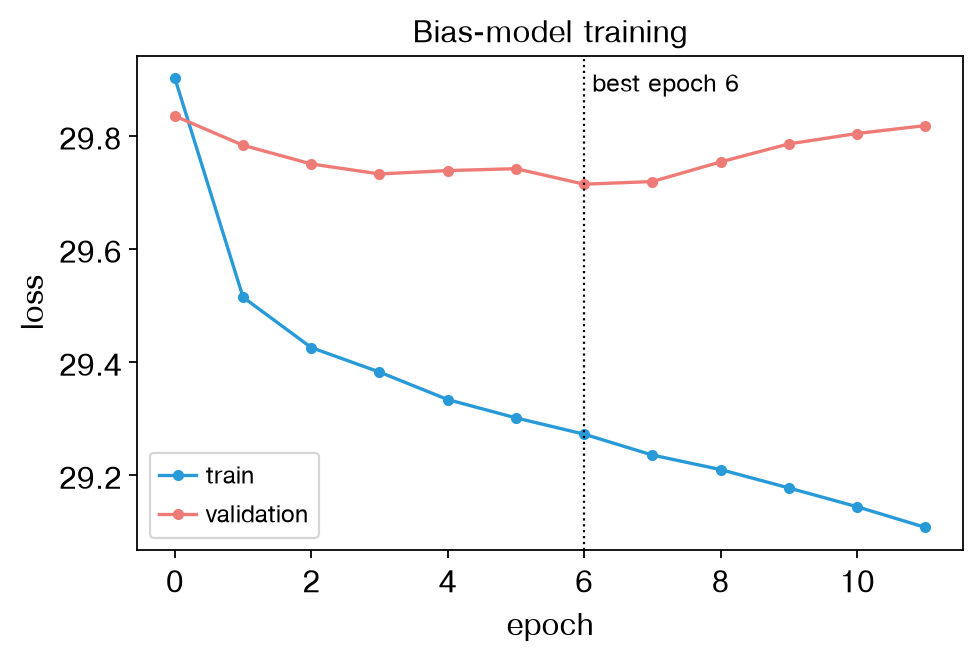

best epoch 6, 1.3 min, params: {'counts_loss_weight': 1.0, 'filters': 128, 'n_dil_layers': 4, 'inputlen': 2114, 'outputlen': 1000, 'max_jitter': 0, 'negative_sampling_ratio': 1.0, 'seed': 1234, 'counts_sum_min_thresh': 0.0, 'counts_sum_max_thresh': 16.0}


In [9]:
res = cbp.train_bias(pk, nonpeaks, fasta, signal, fold, seed=1234, device=device, verbose=False)
h = pd.DataFrame(res.history)
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
ax.plot(h["epoch"], h["loss"], color=MODEL_COLORS["full model"], marker="o", ms=4, label="train")
ax.plot(h["epoch"], h["val_loss"], color=MODEL_COLORS["bias model"], marker="o", ms=4, label="validation")
ax.axvline(res.best_epoch, color="black", ls=":", lw=1)
ax.text(res.best_epoch, 0.97, f" best epoch {res.best_epoch}", transform=ax.get_xaxis_transform(),
        va="top", fontsize=11)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("epoch")
ax.set_ylabel("loss")
ax.set_title("Bias-model training")
ax.legend(loc="lower left", fontsize=11, handlelength=1.5)
plt.show()
print(f"best epoch {res.best_epoch}, {res.seconds / 60:.1f} min, params: {res.params}")

In [10]:
test_bg = cbp.filter_edge_regions(nonpeaks[nonpeaks["chr"].isin(fold["test"])], sizes, 2114)
cbp.evaluate(res.model, test_bg.sample(n=2000, random_state=0), fasta, signal, device=device)

{'count_pearson': 0.4517030116842126,
 'count_spearman': 0.46693940523738425,
 'count_mse': 1.1021212238700462,
 'profile_median_jsd': 0.7812691806295319,
 'n_regions': 2000}

The accessibility model is trained the same way:

```python
full = cbp.train_chrombpnet(pk, nonpeaks, fasta, signal, fold, res.model, seed=1234, device=device)
nobias = full.model.accessibility
```

## The bias model as a Tn5 bias backend

Footprinting compares observed cuts with the cuts expected from Tn5 preference alone. `epi.tl.tn5_bias(method="chrombpnet")` serves any ChromBPNet bias model as that expected-cut track: the one just trained, an official `.h5`, or an ENCODE release name such as `"encode_k562"`. It runs next to PRINT's CNN and the hexamer table.

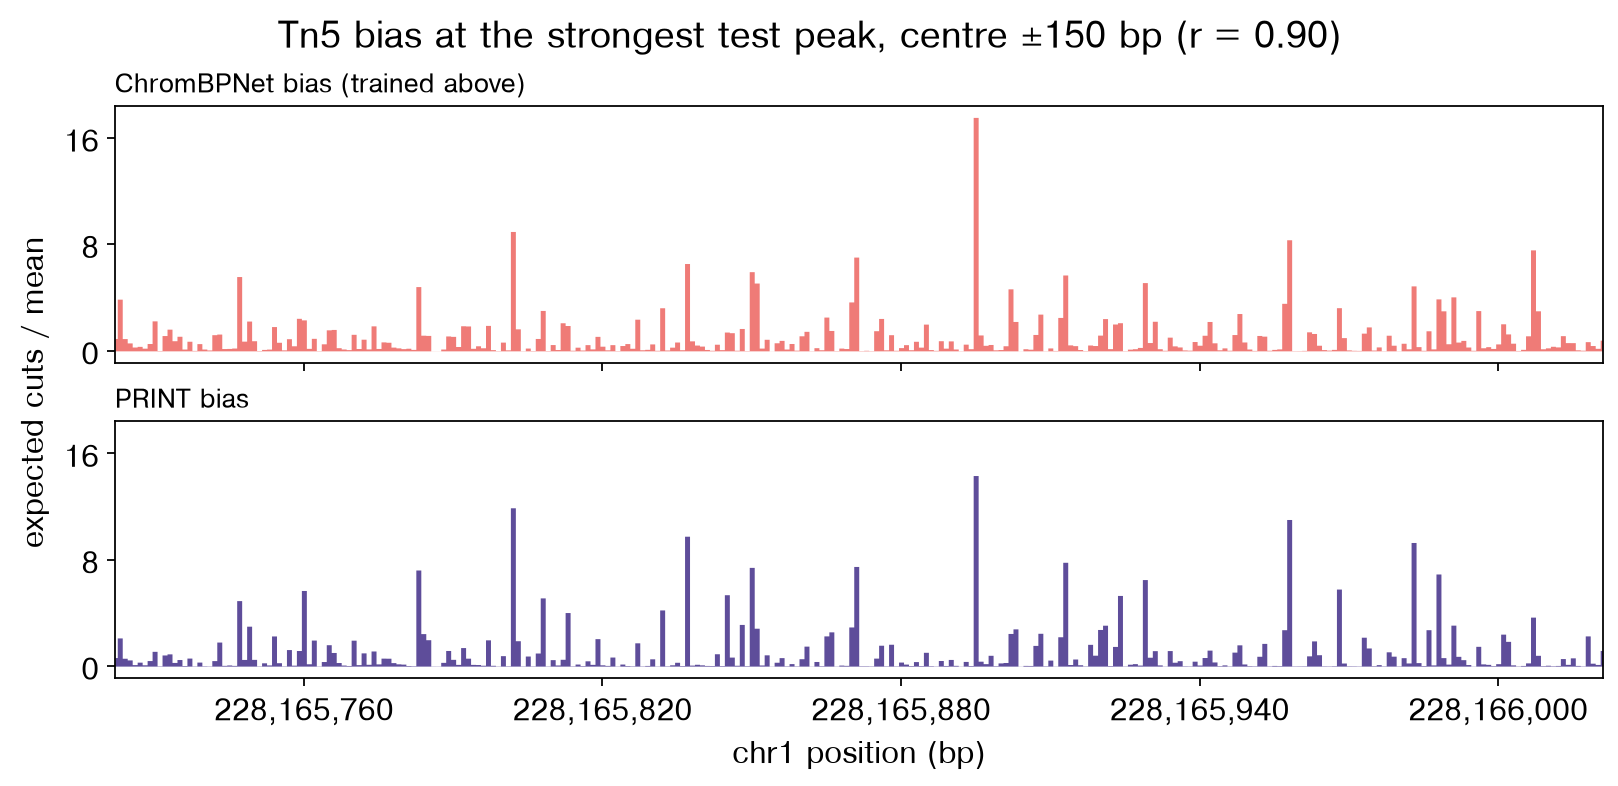

Pearson r between the two bias tracks: 0.896


In [11]:
b_cbp = epi.tl.tn5_bias(fasta, method="chrombpnet", model=res.model, device=device)
b_print = epi.tl.tn5_bias(fasta, method="print")
region = (top["chr"], int(centre - 150), int(centre + 150))
t1, t2 = b_cbp.track(*region), b_print.track(*region)
r_bias = np.corrcoef(t1, t2)[0, 1]
gpos = np.arange(region[1], region[2])
fig, axes = plt.subplots(2, 1, figsize=(10, 4.8), sharex=True, sharey=True, layout="constrained")
for ax, (label, t, color) in zip(axes, [("ChromBPNet bias (trained above)", t1, MODEL_COLORS["bias model"]),
                                        ("PRINT bias", t2, MODEL_COLORS["PRINT bias"])]):
    ax.fill_between(gpos, 0, t / t.mean(), step="mid", color=color, lw=0)
    ax.set_title(label, loc="left", fontsize=12)
    ax.yaxis.set_major_locator(MaxNLocator(3))
axes[-1].set_xlim(gpos[0], gpos[-1])
axes[-1].xaxis.set_major_locator(MaxNLocator(5))
axes[-1].xaxis.set_major_formatter(bp)
axes[-1].set_xlabel(f"{region[0]} position (bp)")
fig.supylabel("expected cuts / mean", fontsize=14)
fig.suptitle(f"Tn5 bias at the strongest test peak, centre ±150 bp (r = {r_bias:.2f})")
plt.show()
print("Pearson r between the two bias tracks:", r_bias.round(3))

Aggregate multi-scale footprints at CTCF core sites in PBMC peaks, with each bias model. The sites are core-regex matches on either strand, within 200 bp of a peak centre, in all peaks on the test chromosomes.

The three panels are not a pure bias-quality ranking. With the PRINT bias, `null="auto"` uses PRINT's learned dispersion null. The ChromBPNet and hexamer biases use the closed-form binomial null, which has no learned overdispersion. So the colour scales are different statistics.

The extraction window is ±450 bp and the view ±150 bp, so large-scale scores near the view edge still have their full flanks.

What the panels show: the small-scale CTCF footprint at the motif, plus a strong signal about 100 bp wide around −130 bp. The second is a positioned nucleosome on one side of strand-oriented CTCF sites, a well-known feature of bound CTCF. It appears at the large scales, where scPrinter-style heatmaps place nucleosomes. The two binomial-null panels score that nucleosome far higher than PRINT's dispersion null, which is calibrated to down-weight broad, high-coverage depletions.

1016 CTCF core sites


  └─ Tn5 bias: scanned 5,000,000 fragments, 9,999,926 cuts; k=6, bias range [0.022, 33.448]


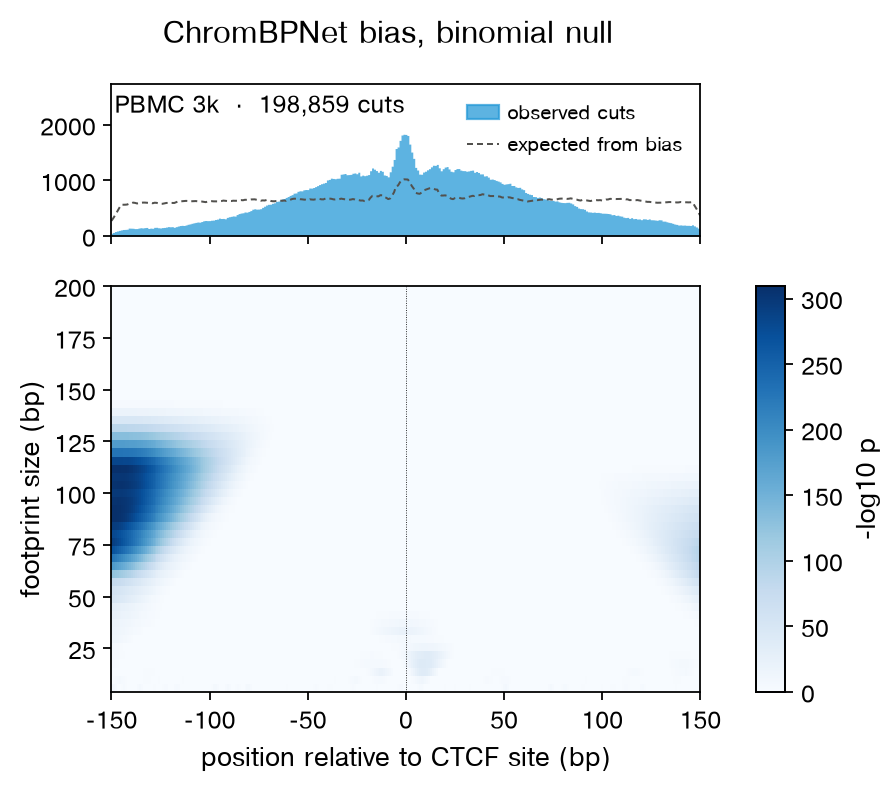

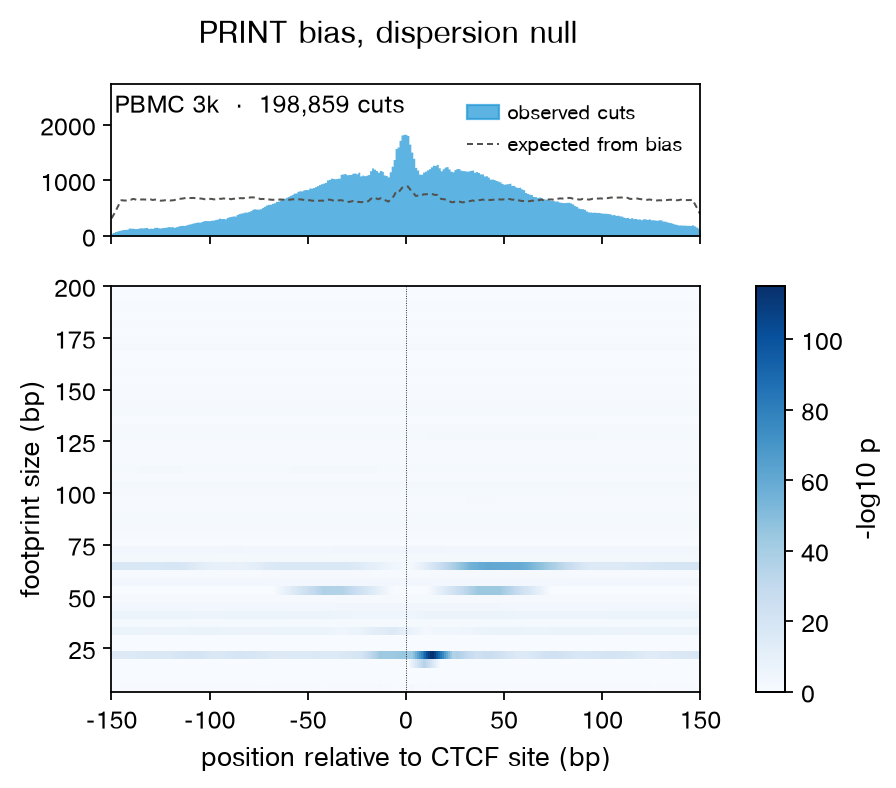

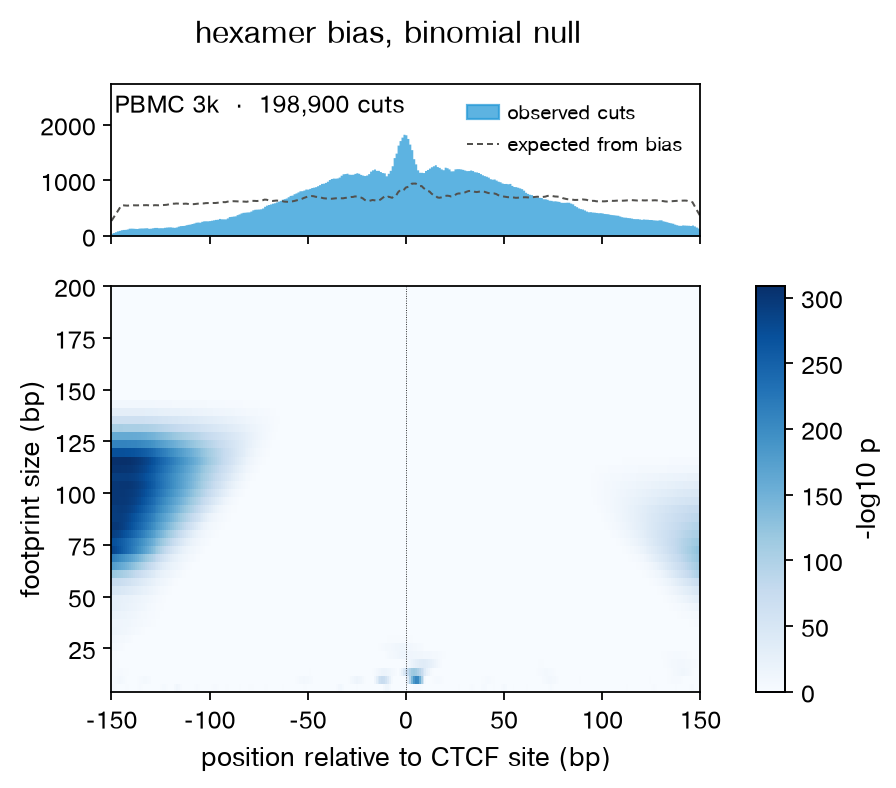

In [12]:
import anndata as ad

bc = pd.read_csv(data["per_barcode_metrics"])
cells = bc.loc[bc["is_cell"] == 1, "barcode"].tolist()
adata = ad.AnnData(obs=pd.DataFrame({"sample": "PBMC 3k"}, index=cells))
adata.uns["files"] = {"fragments": str(data["fragments"])}

fa = __import__("pyfaidx").Fasta(fasta)
core, core_rc = re.compile(r"CCA[CG][CT]AG[AG][GT]GG[CA]"), re.compile(r"[TG]CC[AC][CT]CT[AG][GC]TGG")
all_test = cbp.filter_edge_regions(peaks[peaks["chr"].isin(fold["test"])], sizes, 2114)
sites = []
for c, s, smt in zip(all_test["chr"], all_test["start"], all_test["summit"]):
    mid = s + smt
    sq = str(fa[c][mid - 200:mid + 200]).upper()
    for rx, strand in ((core, "+"), (core_rc, "-")):
        for mt in rx.finditer(sq):
            sites.append((c, mid - 200 + mt.start() + 6, strand))
sites = pd.DataFrame(sites, columns=["chrom", "center", "strand"]).drop_duplicates(["chrom", "center"])
print(len(sites), "CTCF core sites")

results = {}
for name, b in [("ChromBPNet bias", b_cbp), ("PRINT bias", "print"), ("hexamer bias", "kmer")]:
    results[name] = epi.tl.multi_scale_footprint_region(
        adata, sites, groupby="sample", genome=fasta, bias=b, flank=450, verbose=False)


def restyle(fig, tracks=(), fontsize=12):
    # epi.pl's multi-scale plot draws in a light theme of its own (grey ticks,
    # open frames, bold text). This puts it back in the plot_set() look.
    for ax in fig.axes:
        if ax.get_label() != "<colorbar>":
            for sp in ax.spines.values():
                sp.set_visible(True); sp.set_color("k")
            ax.grid(False)
        ax.tick_params(colors="k", labelsize=fontsize - 1)
        for lab in (ax.xaxis.label, ax.yaxis.label):
            lab.set_color("k"); lab.set_fontsize(fontsize)
        for t in ax.texts:
            t.set(color="k", fontsize=fontsize - 1, fontweight="normal")
    for ax in tracks:
        ax.collections[0].set_facecolor(OBSERVED)  # the filled cut track
    if fig._suptitle is not None:
        fig._suptitle.set(color="k", fontweight="normal", fontsize=fontsize + 2)


OBSERVED = "#279AD7"
for name, r in results.items():
    fig, axes = epi.pl.plot_multi_scale_footprint_region(
        r, zoom=150, title=f"{name}, {r.null} null", figsize=(5.4, 5), show=False)
    axes[0].set_xlabel("position relative to CTCF site (bp)")
    restyle(fig, tracks=fig.track_axes)
    tax = fig.track_axes[0]
    tax.set_ylim(0, tax.get_ylim()[1] * 1.3)  # headroom so the label and key clear the cut peak
    tax.legend(handles=[Patch(color=OBSERVED, alpha=0.75, label="observed cuts"),
                        Line2D([], [], color=tax.lines[0].get_color(), lw=0.9, ls=(0, (3, 2)),
                               label="expected from bias")],
               loc="upper right", fontsize=9, handlelength=1.6, frameon=False)
    plt.show()

## Validation against official ChromBPNet

The gates were registered in `tests/parity/chrombpnet/MANIFEST.md` before any run. The reference is the official TensorFlow code (commit `09938fd`) running in a separate environment.

| Gate | What is compared | Result |
|---|---|---|
| G1, same weights | ENCODE GM12878 fold 0 (bias, no-bias, full), 512 sequences, CPU | **pass**: max \|Δ\| logits ≤ 3.2e-5, log counts ≤ 2.9e-6, mean JSD ≤ 5.5e-7 |
| G2, data recipe | insertions from fragments vs the official bigWig; bias and ChromBPNet hyper-parameter steps; bias rescaling | **pass, exact**: 2,000/2,000 windows identical; identical filtered region sets and loss weights; rescaled bias within 5.1e-6 |
| G3, training from scratch | PBMC 3k, fold 0 restricted, 3 seeds per side | **pass, 4/4**: count Pearson 0.691 vs 0.702 (tolerance 0.02); median JSD 0.513 vs 0.515; bias count Pearson 0.427 vs 0.427; CTCF footprint depth within the large seed spread of both sides |
| G5, Tn5 bias backend | `ChromBPNetBias.track` vs direct prediction | **pass, bit-exact** |

Two caveats:
- On count Pearson every Epione seed is about 0.01 below every official seed, inside the tolerance but consistent.
- The footprint-depth metric is too noisy at this sequencing depth to mean much.

Full tables, including timings, are in the MANIFEST.